## If recent paces continue, does the share ranking move?

Notebook 2 compares counties with each other. A change that every county shares does not change implied Kaiser share. This notebook takes the measures that remain in that model and asks how counties move relative to one another.

The measures are the uninsured rate, unemployment, population, and the benchmark Silver premium. Kaiser's gap to the benchmark is not projected. Income, poverty, and carrier count stay where they are.

The pace is 2019–2024. The uninsured rate fell from 2016 to 2018 and then leveled off, so the earlier drop is not treated as a pace that continues. Unemployment from 2019 to 2024 runs through the 2020 spike, so it is held at the 2024 rate rather than extended. Premiums use each county's 2019–2024 slope, not the jump from 2016 to 2019.

The continuation covers counties that were offered during 2016–2024 and are still offered in 2025. Five and ten years are counted from 2024 for the uninsured rate and population, and from 2025 for the benchmark premium. Los Angeles is not scored, because it has no benchmark premium. Monterey was not offered in the estimation years, so it is an opening case of its own.


In [1]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import HTML, Markdown, display

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
})

con = duckdb.connect("../data/processed/analysis.duckdb", read_only=True)
market = con.sql("select * from main_marts.mart_cty_yr_market").df()
performance = con.sql("select * from main_marts.mart_cty_yr_performance").df()
socioeconomic = con.sql("select * from main_marts.mart_cty_yr_socioeconomic").df()
panel = (
    market.merge(performance, on=["county_fips", "year"], how="left", suffixes=("", "_performance"))
    .merge(socioeconomic, on=["county_fips", "year"], how="left", suffixes=("", "_socio"))
)

offered_history = panel[panel["kp_offered"] & panel["year"].between(2016, 2024)].copy()
means = offered_history.groupby(["county_fips", "county_name"], as_index=False)[[
    "kp_market_share",
    "population_total",
    "median_household_income",
    "poverty_rate",
    "uninsured_rate",
    "unemployment_rate",
    "carrier_count",
    "benchmark_silver_premium",
]].mean()
means["log_population"] = np.log(means["population_total"])
means["income_10k"] = means["median_household_income"] / 10000
estimation = means.dropna(subset=[
    "kp_market_share",
    "log_population",
    "income_10k",
    "poverty_rate",
    "uninsured_rate",
    "unemployment_rate",
    "carrier_count",
    "benchmark_silver_premium",
])
model = smf.ols(
    "kp_market_share ~ log_population + income_10k + poverty_rate + uninsured_rate "
    "+ unemployment_rate + carrier_count + benchmark_silver_premium",
    data=estimation,
).fit(cov_type="HC1")


def annual_slope(frame, column):
    year = frame["year"].to_numpy(float)
    values = frame[column].to_numpy(float)
    usable = np.isfinite(values)
    if usable.sum() < 4:
        return np.nan
    return float(np.polyfit(year[usable], values[usable], 1)[0])


slope_rows = []
pace_window = panel[panel["year"].between(2019, 2024)]
for county_fips, county_frame in pace_window.groupby("county_fips"):
    county_frame = county_frame.sort_values("year")
    slope_rows.append({
        "county_fips": county_fips,
        "slope_uninsured": annual_slope(county_frame, "uninsured_rate"),
        "slope_population": annual_slope(county_frame, "population_total"),
        "slope_benchmark": annual_slope(county_frame, "benchmark_silver_premium"),
    })
slopes = pd.DataFrame(slope_rows)

current = panel.loc[panel["year"] == 2024, [
    "county_fips", "county_name", "uninsured_rate", "unemployment_rate", "population_total",
]].merge(slopes, on="county_fips")
year_2025 = panel.loc[panel["year"] == 2025, [
    "county_fips", "kp_offered", "kp_market_share", "kp_enrollment", "benchmark_silver_premium",
]]
scenario = current.merge(year_2025, on="county_fips")
scenario = scenario[
    scenario["kp_offered"] & scenario["county_fips"].isin(estimation["county_fips"])
].copy()


def implied_change(frame, years):
    current_uninsured = frame["uninsured_rate"].to_numpy()
    future_uninsured = np.maximum(current_uninsured + frame["slope_uninsured"].to_numpy() * years, 0)
    uninsured_component = model.params["uninsured_rate"] * (
        (future_uninsured - future_uninsured.mean()) - (current_uninsured - current_uninsured.mean())
    )

    future_population = np.maximum(
        frame["population_total"].to_numpy() + frame["slope_population"].to_numpy() * years,
        1000,
    )
    current_log = np.log(frame["population_total"].to_numpy())
    future_log = np.log(future_population)
    population_component = model.params["log_population"] * (
        (future_log - future_log.mean()) - (current_log - current_log.mean())
    )

    current_premium = frame["benchmark_silver_premium"].to_numpy()
    future_premium = np.maximum(current_premium + frame["slope_benchmark"].to_numpy() * years, 0)
    premium_component = model.params["benchmark_silver_premium"] * (
        (future_premium - future_premium.mean()) - (current_premium - current_premium.mean())
    )
    return (uninsured_component + population_component + premium_component) * 100


scenario["change_5y"] = implied_change(scenario, 5)
scenario["change_10y"] = implied_change(scenario, 10)
median_share = scenario["kp_market_share"].median()
scenario["share_group"] = np.where(
    scenario["kp_market_share"] >= median_share,
    "At or above median",
    "Below median",
)

offered_medians = (
    panel[panel["kp_offered"] & panel["year"].between(2016, 2024)]
    .groupby("year", as_index=False)
    .agg(
        uninsured_rate=("uninsured_rate", "median"),
        unemployment_rate=("unemployment_rate", "median"),
        benchmark_silver_premium=("benchmark_silver_premium", "median"),
    )
)

pace = pd.DataFrame([
    {
        "measure": "Uninsured rate",
        "median annual change": f"{scenario['slope_uninsured'].median():.2f} points",
        "25th percentile": f"{scenario['slope_uninsured'].quantile(.25):.2f}",
        "75th percentile": f"{scenario['slope_uninsured'].quantile(.75):.2f}",
    },
    {
        "measure": "Unemployment rate",
        "median annual change": "Held at 2024",
        "25th percentile": "",
        "75th percentile": "",
    },
    {
        "measure": "Population",
        "median annual change": f"{scenario['slope_population'].median():,.0f}",
        "25th percentile": f"{scenario['slope_population'].quantile(.25):,.0f}",
        "75th percentile": f"{scenario['slope_population'].quantile(.75):,.0f}",
    },
    {
        "measure": "Benchmark Silver premium",
        "median annual change": f"${scenario['slope_benchmark'].median():.2f}",
        "25th percentile": f"${scenario['slope_benchmark'].quantile(.25):.2f}",
        "75th percentile": f"${scenario['slope_benchmark'].quantile(.75):.2f}",
    },
])
display(Markdown("**Annual pace, 2019–2024, across the counties in the continuation**"))
display(HTML(pace.to_html(index=False)))

group_change = (
    scenario.groupby("share_group", as_index=False)[["change_5y", "change_10y"]]
    .median()
)
high_5 = group_change.loc[group_change["share_group"].eq("At or above median"), "change_5y"].iloc[0]
low_5 = group_change.loc[group_change["share_group"].eq("Below median"), "change_5y"].iloc[0]
high_10 = group_change.loc[group_change["share_group"].eq("At or above median"), "change_10y"].iloc[0]
low_10 = group_change.loc[group_change["share_group"].eq("Below median"), "change_10y"].iloc[0]
display(Markdown(
    f"Over five years the median county at or above the current median share moves "
    f"**{high_5:+.1f}** percentage points, and the median county below it moves **{low_5:+.1f}**. "
    f"Over ten years those medians are **{high_10:+.1f}** and **{low_10:+.1f}**. "
    f"The middle half of counties is between **{scenario['change_5y'].quantile(.25):+.1f}** and "
    f"**{scenario['change_5y'].quantile(.75):+.1f}** points at five years."
))

ranking = scenario.sort_values("kp_market_share", ascending=False)
ranking_view = pd.DataFrame({
    "county": ranking["county_name"].str.replace(" County", "", regex=False),
    "share_2025": (ranking["kp_market_share"] * 100).map(lambda value: f"{value:.1f}%"),
    "population_2024": ranking["population_total"].map(lambda value: f"{value:,.0f}"),
    "implied_change_5y": ranking["change_5y"].map(lambda value: f"{value:+.1f}"),
    "implied_change_10y": ranking["change_10y"].map(lambda value: f"{value:+.1f}"),
})
display(HTML(ranking_view.to_html(index=False)))


**Annual pace, 2019–2024, across the counties in the continuation**

measure,median annual change,25th percentile,75th percentile
Uninsured rate,-0.08 points,-0.18,-0.01
Unemployment rate,Held at 2024,,
Population,614,"-1,541","3,967"
Benchmark Silver premium,$1.28,$-2.31,$5.74


Over five years the median county at or above the current median share moves **-0.2** percentage points, and the median county below it moves **+0.8**. Over ten years those medians are **-0.3** and **+1.6**. The middle half of counties is between **-6.3** and **+5.8** points at five years.

county,share_2025,population_2024,implied_change_5y,implied_change_10y
Solano,80.4%,"451,918",-8.5,-17.0
Alameda,79.8%,"1,649,473",+0.7,+1.5
Contra Costa,77.4%,"1,165,012",-8.4,-16.7
San Mateo,73.0%,"742,340",+7.5,+15.0
San Joaquin,72.9%,"797,334",-8.1,-16.1
Sonoma,69.9%,"485,040",-0.7,-1.3
Napa,69.5%,"134,869",-7.1,-14.3
Santa Cruz,68.2%,"264,926",+6.7,+13.4
Sacramento,60.7%,"1,594,006",+5.9,+11.8
Stanislaus,59.7%,"553,990",-9.6,-19.2


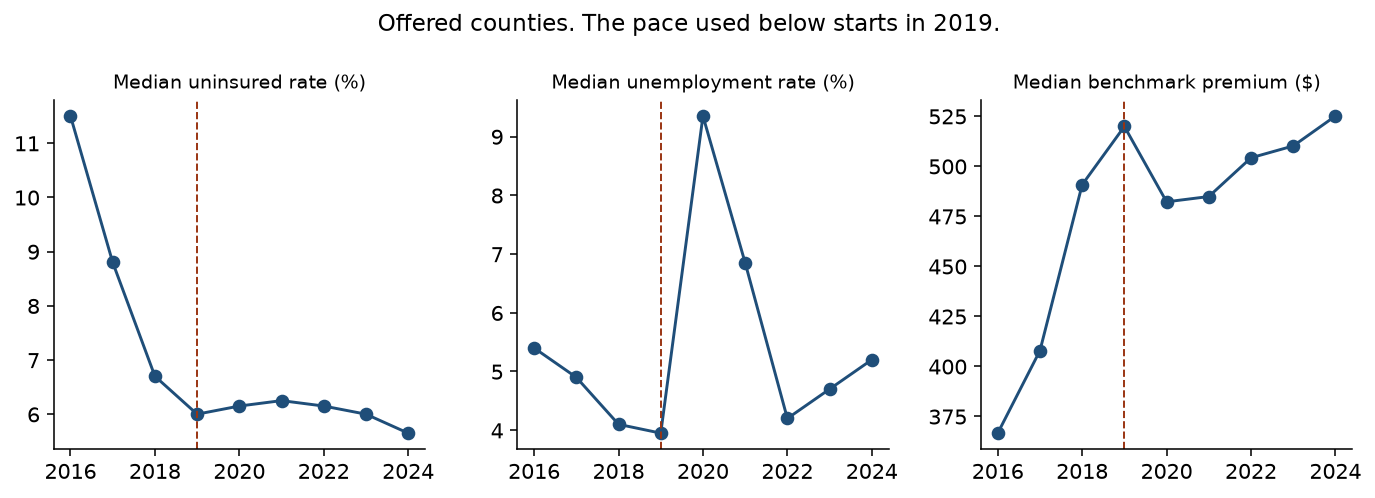

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
history = [
    ("uninsured_rate", "Median uninsured rate (%)"),
    ("unemployment_rate", "Median unemployment rate (%)"),
    ("benchmark_silver_premium", "Median benchmark premium ($)"),
]
for ax, (column, title) in zip(axes, history):
    ax.plot(offered_medians["year"], offered_medians[column], marker="o", color="#1f4e79")
    ax.axvline(2019, color="#9a3412", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(2016, 2025, 2))
fig.suptitle("Offered counties. The pace used below starts in 2019.", fontsize=12)
fig.tight_layout()


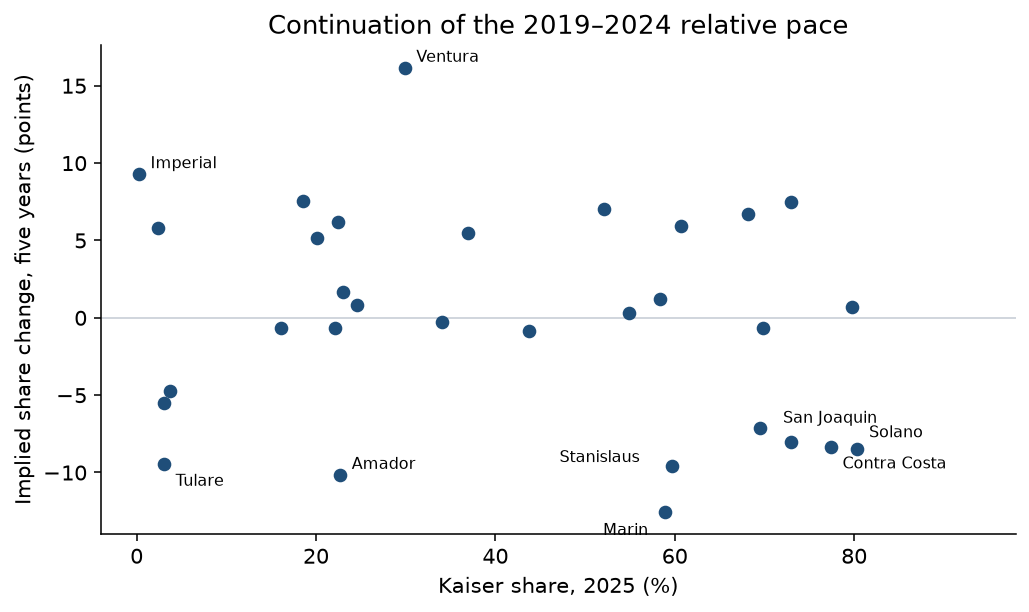

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axhline(0, color="#d0d5dd", linewidth=1)
ax.scatter(
    scenario["kp_market_share"] * 100,
    scenario["change_5y"],
    s=36,
    color="#1f4e79",
    zorder=3,
)
labels = scenario.loc[scenario["change_5y"].abs() >= 8].copy()
labels["county"] = labels["county_name"].str.replace(" County", "", regex=False)
offsets = {
    "Imperial": (6, 3),
    "Tulare": (6, -11),
    "Amador": (6, 3),
    "Ventura": (6, 3),
    "Marin": (-32, -12),
    "Stanislaus": (-58, 2),
    "San Joaquin": (-4, 10),
    "Contra Costa": (6, -11),
    "Solano": (6, 6),
}
for _, row in labels.iterrows():
    ax.annotate(
        row["county"],
        (row["kp_market_share"] * 100, row["change_5y"]),
        textcoords="offset points",
        xytext=offsets.get(row["county"], (6, 4)),
        fontsize=8,
    )
ax.set_xlim(-4, 98)
ax.set_xlabel("Kaiser share, 2025 (%)")
ax.set_ylabel("Implied share change, five years (points)")
ax.set_title("Continuation of the 2019–2024 relative pace")
fig.tight_layout()


## Monterey, the opening

Monterey is offered in 2025 and was not offered in the years the model was estimated. It is not in the continuation table. The comparison is to Santa Cruz, which has the same 2025 benchmark premium, and to the counties already at or above the median share.


In [5]:
profile_counties = panel.loc[
    (panel["year"] == 2025) & panel["kp_offered"],
    ["county_fips", "county_name", "benchmark_silver_premium", "kp_market_share"],
].merge(
    panel.loc[
        panel["year"] == 2024,
        ["county_fips", "uninsured_rate", "unemployment_rate", "population_total",
         "median_household_income", "poverty_rate", "carrier_count"],
    ],
    on="county_fips",
)
profile_counties["share_group"] = np.where(
    profile_counties["kp_market_share"] >= profile_counties["kp_market_share"].median(),
    "At or above median",
    "Below median",
)

def condition_row(frame, label):
    return {
        "place": label,
        "share_2025": f"{frame['kp_market_share'].mean() * 100:.1f}%",
        "uninsured_2024": f"{frame['uninsured_rate'].mean():.1f}%",
        "unemployment_2024": f"{frame['unemployment_rate'].mean():.1f}%",
        "benchmark_2025": f"${frame['benchmark_silver_premium'].mean():,.0f}",
        "population_2024": f"{frame['population_total'].mean():,.0f}",
    }

monterey = profile_counties.loc[profile_counties["county_name"].eq("Monterey County")].iloc[0]
santa_cruz = profile_counties.loc[profile_counties["county_name"].eq("Santa Cruz County")]
high_share = profile_counties.loc[profile_counties["share_group"].eq("At or above median")]
comparison = pd.DataFrame([
    condition_row(profile_counties.loc[profile_counties["county_name"].eq("Monterey County")], "Monterey"),
    condition_row(santa_cruz, "Santa Cruz"),
    condition_row(high_share, "At or above median share"),
])
display(HTML(comparison.to_html(index=False)))

score = (
    model.params["Intercept"]
    + model.params["log_population"] * np.log(monterey["population_total"])
    + model.params["income_10k"] * monterey["median_household_income"] / 10000
    + model.params["poverty_rate"] * monterey["poverty_rate"]
    + model.params["uninsured_rate"] * monterey["uninsured_rate"]
    + model.params["unemployment_rate"] * monterey["unemployment_rate"]
    + model.params["carrier_count"] * monterey["carrier_count"]
    + model.params["benchmark_silver_premium"] * monterey["benchmark_silver_premium"]
)
display(Markdown(
    f"Scoring Monterey's 2024 conditions and 2025 premium with model 2 gives **{score:.0%}** share. "
    f"Its actual 2025 share is **{monterey['kp_market_share']:.0%}**. "
    f"The in-sample residual is about **{model.resid.std() * 100:.0f}** percentage points, "
    "and 2025 is the first year the service area is open. "
    "The score is pulled up by the benchmark premium Monterey shares with Santa Cruz. "
    "Its uninsured rate sits with the below-median counties, and so does its share."
))


place,share_2025,uninsured_2024,unemployment_2024,benchmark_2025,population_2024
Monterey,29.1%,9.6%,7.3%,$744,"437,613"
Santa Cruz,68.2%,4.9%,5.9%,$744,"264,926"
At or above median share,61.8%,4.6%,4.8%,$624,"690,944"


Scoring Monterey's 2024 conditions and 2025 premium with model 2 gives **61%** share. Its actual 2025 share is **29%**. The in-sample residual is about **14** percentage points, and 2025 is the first year the service area is open. The score is pulled up by the benchmark premium Monterey shares with Santa Cruz. Its uninsured rate sits with the below-median counties, and so does its share.

## What this can support

The counties at or above the median share and the counties below it do not trade places. Five more years of the recent relative pace moves the median county in each group by about a point. The mean-share gap between those groups is about 45 points. Ten years is the same annual pace run for longer, so the county tails get wider without a new fact.

The movement that does appear comes from counties whose uninsured rate or benchmark premium is changing faster than the others. Population growth barely moves implied share. A common rise or fall in premiums drops out, because the model is about which counties are expensive, not about the premium level rising everywhere.

This is not an enrollment forecast. It does not add counties to the footprint, and it does not use Kaiser's premium gap. Offered still includes counties where only some ZIP codes are in the service area, and Los Angeles still has no county premium.
